<center><b><font style="color: orange" size="5">Lab Session 2: The support vector machine</font></b></center>
&ensp;

> Student 1:
>> First Name: Vu Minh Dang

>> Last Name: LE

# **Import dependencies:**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **1. Solving the hard-threshold SVM problem**

## **Dataset Generation and Verification**

- I generate a 2D toy dataset composed of two linearly separable point clouds with finite support. Each class is sampled from a uniform distribution over a box centered at the prescribed means $\mu_+ = (0.5, 0)$ and $\mu_- = (0.5, 0)$.
- The box half_width $h$ is chosen such that $h_x < 0.5$, which gurantees that the x-intervals of the two classes do not overlap and therefore the dataset is separable.

In [69]:
def make_toy_data(m_per_class=80, half_width=(0.45, 0.45), seed=0):
    """
    Lab toy data:
      - two separable clouds
      - uniform distributions (finite support)
      - means mu+ = (1/2, 0), mu- = (-1/2, 0)
    Output:
      X: (2, m) columns are samples
      y: (m,) in {-1, +1}
      mu_pos, mu_neg: (2,)
      half_width: (2,)
    """
    rng = np.random.default_rng(seed)

    mu_pos = np.array([0.5, 0.0], dtype=float)
    mu_neg = np.array([-0.5, 0.0], dtype=float)
    half_width = np.array(half_width, dtype=float)

    # For these means (separation along x), guarantee separability by choosing half_width_x < 0.5
    if half_width[0] >= 0.5:
        raise ValueError("Choose half_width[0] < 0.5 to keep the two x-intervals disjoint.")

    U_pos = rng.uniform(-half_width[:, None], half_width[:, None], size=(2, m_per_class))
    U_neg = rng.uniform(-half_width[:, None], half_width[:, None], size=(2, m_per_class))

    X_pos = mu_pos[:, None] + U_pos
    X_neg = mu_neg[:, None] + U_neg

    X = np.concatenate([X_pos, X_neg], axis=1)  # (2, 2*m_per_class)
    y = np.concatenate([np.ones(m_per_class), -np.ones(m_per_class)]).astype(float)  # (m,)

    return X, y, mu_pos, mu_neg, half_width

- To check the dataset, I firstly verify the label vector shape: in NumPy, $y.T$ does nothing when $y$ is 1D, so we use np.atleast_2d(y).T whenever a true column vector is required.
- Then I visualize the dataset and plot a separating hyperplane $w^Tx - b = 0$, for example, the vertical line $x = 0$ for this construction, to confirm that all samples lie on the correct side of the boundary.

In [53]:
def y_shape_check(y):
    """
    Prints exactly the pitfall:
      - y is (m,) -> y.T does nothing
      - use np.atleast_2d(y).T to get (m,1)
    """
    y1 = np.asarray(y).reshape(-1)          # (m,)
    y_col = np.atleast_2d(y1).T             # (m,1)

    print("y1.shape =", y1.shape)
    print("y1.T.shape =", y1.T.shape, " <- does nothing for 1D")
    print("np.atleast_2d(y1).T.shape =", y_col.shape, " <- real column")

    return y1, y_col

In [54]:
def separability_check_with_line(X, y, w, b):
    """
    Checks that the chosen separating hyperplane (w,b) separates the dataset:
    sign(w^T x - b) matches label y in {-1, +1}.
    """
    X = np.asarray(X)
    y = np.asarray(y).reshape(-1)
    w = np.asarray(w).reshape(-1)
    b = float(b)

    scores = (w @ X) - b
    ok = np.all(y * scores > 0)

    n_wrong = int(np.sum(y * scores <= 0))
    print("Separable by the chosen line?", ok)
    print("Number of misclassified points:", n_wrong)

    return ok, scores

In [84]:
def plot_dataset_and_boundary(X, y, w, b, title="Toy dataset + separating hyperplane"):
    X = np.asarray(X, float)
    y = np.asarray(y).reshape(-1)
    w = np.asarray(w, float).reshape(-1)
    b = float(b)

    pos = (y == 1)
    neg = (y == -1)

    fig, ax = plt.subplots(figsize=(7,6))
    ax.scatter(X[0, pos], X[1, pos], marker="+", label="Class +1")
    ax.scatter(X[0, neg], X[1, neg], marker="o", label="Class -1")

    # plot boundary
    x_min, x_max = X[0,:].min()-0.5, X[0,:].max()+0.5
    y_min, y_max = X[1,:].min()-0.5, X[1,:].max()+0.5
    xs = np.linspace(x_min, x_max, 300)

    if abs(w[1]) > 1e-6:
        ys = (b - w[0]*xs) / w[1]
        ax.plot(xs, ys, label="Boundary: $w^T x - b = 0$")
    else:
        x0 = b / (w[0] + 1e-12)
        ax.axvline(x0, label="Boundary: $w^T x - b = 0$")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_aspect("equal", adjustable="box")

    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

y1.shape = (160,)
y1.T.shape = (160,)  <- does nothing for 1D
np.atleast_2d(y1).T.shape = (160, 1)  <- real column
Separable by the chosen line? True
Number of misclassified points: 0


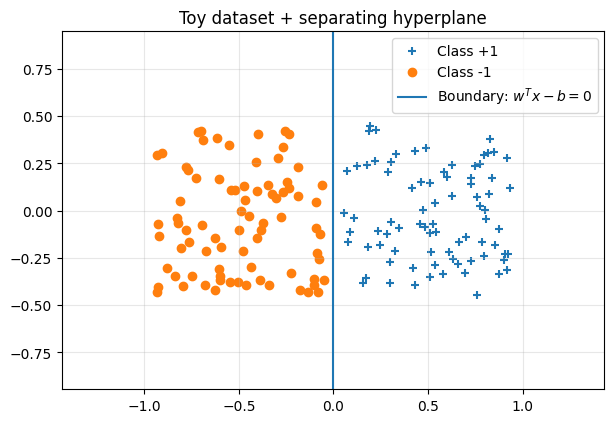

In [86]:
X, y, mu_pos, mu_neg, half_width = make_toy_data(m_per_class=80, half_width=(0.45, 0.45), seed=1)

y1, y_col = y_shape_check(y)

w = np.array([1.0, 0.0])
b = 0.0

ok, scores = separability_check_with_line(X, y1, w, b)

plot_dataset_and_boundary(X, y1, w, b)

## **Build the dual matrix Q**

With $X$ shaped $(n,m)$ and $y$ shaped $(m,)$, the dual uses $Q = \left(X^T.X\right) * \text{outer}\left(y,y\right)$

In [57]:
def build_Q(X, y):
    """
    Build Q = (X^T X) ⊙ (y y^T)
    X: (n,m), y: (m,)
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    G = X.T @ X                 # (m,m)
    Q = G * np.outer(y, y)      # (m,m)
    return Q

## **Projections for the constraint set $\lambda \geq 0, y^T \lambda = 0$**

The "hard-threshold/prox" step is a projection onto a the intersection:
- $\lambda \geq 0$.
- $y^T \lambda = 0$.

In [58]:
def proj_nonnegative(z):
    return np.maximum(z, 0.0)

def proj_hyperplane_y(z, y):
    """
    Projection onto {u : y^T u = 0}
    """
    y = np.asarray(y, dtype=float).reshape(-1)
    denom = float(np.dot(y, y))
    return z - y * (np.dot(y, z) / denom)

def proj_intersection_dykstra(z, y, max_iter=200, tol=1e-10):
    """
    Project onto {lambda >= 0} ∩ {y^T lambda = 0} via Dykstra.
    """
    y = np.asarray(y, dtype=float).reshape(-1)
    x = z.copy()
    p = np.zeros_like(z)
    q = np.zeros_like(z)

    for _ in range(max_iter):
        x_old = x

        # A: lambda >= 0
        a = proj_nonnegative(x + p)
        p = x + p - a

        # B: y^T lambda = 0
        b = proj_hyperplane_y(a + q, y)
        q = a + q - b

        x = b

        if np.linalg.norm(x - x_old) <= tol * (1.0 + np.linalg.norm(x_old)):
            break

    return x

## **Step size $\rho$ using Lipschitz constant $L$**

In [59]:
def power_iteration_lmax(Q, n_iter=200, seed=0):
    """
    Approximate largest eigenvalue of symmetric PSD matrix Q.
    """
    rng = np.random.default_rng(seed)
    v = rng.normal(size=(Q.shape[0],))
    v /= np.linalg.norm(v) + 1e-12

    for _ in range(n_iter):
        v = Q @ v
        nrm = np.linalg.norm(v)
        if nrm < 1e-14:
            return 0.0
        v /= nrm

    return float(v.T @ (Q @ v))

## **Forward-Backward solver for the dual**

In [60]:
def hard_svm_dual_forward_backward(X, y, n_iter=2000, proj_iter=150, gamma=None, seed=0):
    """
    Forward–Backward on the hard-margin dual.
    Returns:
      lam: (m,)
      cost: (n_iter,)  where cost[k] = 0.5 lam^T Q lam - 1^T lam
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n, m = X.shape

    Q = build_Q(X, y)
    ones = np.ones(m, dtype=float)

    # gamma <= 1/L
    L = power_iteration_lmax(Q, seed=seed)
    if gamma is None:
        gamma = 1.0 / (L + 1e-12)

    lam = np.zeros(m, dtype=float)
    cost = np.zeros(n_iter, dtype=float)

    for k in range(n_iter):
        # forward (gradient) step
        z = lam - gamma * (Q @ lam - ones)

        # backward (projection) step
        lam = proj_intersection_dykstra(z, y, max_iter=proj_iter)

        cost[k] = 0.5 * lam @ (Q @ lam) - ones @ lam

    return lam, cost

## **Recover $w$ and $b$ from $\lambda$**

In [61]:
def compute_w_b_from_lambda(X, y, lam, eps_sv=1e-8):
    """
    w = sum_i lam_i y_i x_i = X @ (y*lam)
    b = average_i (w^T x_i - y_i) over support vectors (lam_i > eps)
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    lam = np.asarray(lam, dtype=float).reshape(-1)

    w = X @ (y * lam)

    sv = np.where(lam > eps_sv)[0]
    if sv.size == 0:
        b = 0.0
    else:
        b_vals = (w @ X[:, sv]) - y[sv]
        b = float(np.mean(b_vals))

    return w, b

## **Log-log plot of the cost**

In [62]:
def plot_cost_loglog(cost, title="Dual cost convergence (log-log)"):
    cost = np.asarray(cost, dtype=float)
    y = np.maximum(cost - np.min(cost), 1e-18)

    plt.figure()
    plt.loglog(y)
    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel("cost(k) - min(cost)")
    plt.show()

## **Run the code**

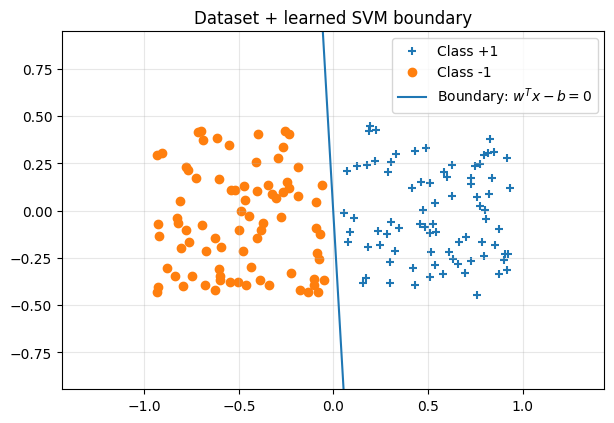

In [87]:
lam, cost = hard_svm_dual_forward_backward(X, y1, n_iter=2500, proj_iter=200, gamma=None, seed=0)

w, b = compute_w_b_from_lambda(X, y1, lam, eps_sv=1e-8)
plot_dataset_and_boundary(X, y1, w, b, title="Dataset + learned SVM boundary")

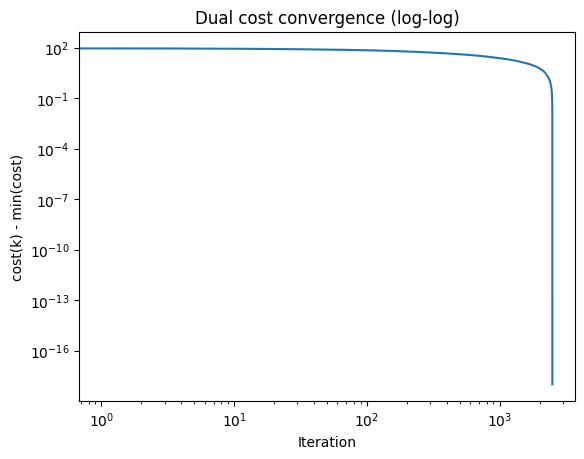

In [64]:
plot_cost_loglog(cost, title="Dual cost convergence (log-log)")

In [15]:
print("w =", w)
print("b =", b)
print("||w|| =", np.linalg.norm(w))

w = [11.0765712   0.64205574]
b = -0.013855486305545414
||w|| = 11.095164038875186


In [16]:
separability_check_with_line(X, y1, w, b)

Separable by the chosen line? True
Number of misclassified points: 0


(np.True_,
 array([  5.76265123,   9.8957423 ,   2.15996143,   9.85808008,
          3.86773222,   4.53510552,   9.00706327,   4.45309054,
          5.97438997,   0.7365206 ,   8.18995562,   5.7466512 ,
          3.7948028 ,   8.14190271,   3.45296478,   5.04302448,
          1.67621573,   4.66322927,   2.526815  ,   3.31284934,
          8.13691649,   3.32331423,   5.6167674 ,  10.42092322,
         10.33365407,   7.70163374,   5.98836237,   3.15249377,
          2.45590539,  10.08840416,   5.57183326,   1.47610619,
          6.64324634,   8.46242014,   6.79301412,   9.4975748 ,
          0.89086643,   5.79144941,   5.24210017,   1.16377519,
          7.01102409,   9.26379436,   6.60952992,   3.08256758,
          8.91057156,   5.57035489,   5.43517655,   7.90309556,
          1.91737865,   8.63106962,   7.27128218,   8.45850677,
          2.7504562 ,   8.72509814,   2.64320763,   1.53049343,
          9.14941265,   9.39510876,   9.41538486,   5.27231745,
          3.05526669,   0.631

# **2. Soft-threshold SVM problem**

##**Question 8**

- In the reformulation of the soft-threshold SVM problem, we introduce extended variables $\tilde{x}_i = [x_i^T, -1]^T$ and $\tilde{w} = [w^T, b]^T$, leading the matrix $\tilde{X} \in \mathbb{R}^{(n+1) \times m}$.
- The assumption is that if $m \geq n+1$ and $\tilde{X} \tilde{X}^T$ is invertible (full rank), we can use the pseudoinverse $\tilde{X}^\# = (\tilde{X} \tilde{X}^T)^{-1} \tilde{X}$. It's a very common case in machine learning where we have many samples, few features.
- If $m \leq n$ then $rank(\tilde{X}) \leq m  \leq n$, so $\tilde{X} \tilde{X}^T$ cannot be invertible. Therefore, the "reduce-to-$\zeta$-only" formulation isn't applicable.

##**Question 9**

Prove $f_1(z) = max\{0, 1-z\}$ is convex

- This is the maximum of two affine convex function.
- Max of convex functions is convex.

Prox operator (scalar): for $\tau > 0$,

$$
\operatorname{prox}_{\tau f_1}(z) = \arg\min_u \frac{1}{2}(u - z)^2 + \tau \max(0, 1 - u)
$$

Closed-form:

$$
\operatorname{prox}_{\tau f_1}(z) =
\begin{cases}
z & z > 1 + \tau \\
1 & 1  \leq z \leq 1 + \tau \\
z + \tau & z < 1
\end{cases}
$$

It's the projection onto the shifted interval.



In [17]:
def prox_hinge(z, tau):
    """
    Proximal operator of tau * f1 where f1(t) = max(0, 1 - t).
    """
    z = np.asarray(z, dtype=float)
    out = z.copy()

    high = (z > 1.0 + tau)
    out[high] = z[high]

    mid = (z >= 1.0) & (z <= 1.0 + tau)
    out[mid] = 1.0

    low = (z < 1.0)
    out[low] = z[low] + tau

    return out

##**Question 10**

In [18]:
def make_gaussian_toy_data(m_per_class=100, seed=0):
    """
    Generate overlapping 2D Gaussian clouds.
    """
    rng = np.random.default_rng(seed)
    cov = 0.5 * np.eye(2)
    X_pos = rng.multivariate_normal([1.0, 0.0], cov, m_per_class).T
    X_neg = rng.multivariate_normal([-1.0, 0.0], cov, m_per_class).T
    X = np.concatenate([X_pos, X_neg], axis=1)
    y = np.concatenate([np.ones(m_per_class), -np.ones(m_per_class)]).astype(float)
    return X, y

def build_augmented_data(X, y):
    """
    Build augmented data matrix X_aug where each column is [x_i; -1].
    """
    n, m = X.shape
    X_aug = np.vstack([X, -np.ones((1, m))])  # Add -1 row at bottom
    return X_aug

In [19]:
def compute_soft_svm_matrices(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n, m = X.shape

    X_aug = np.vstack([X, -np.ones((1, m))])  # (n+1,m)

    P_w = np.eye(n + 1)
    P_w[-1, -1] = 0.0

    XXT_aug = X_aug @ X_aug.T
    inv = np.linalg.inv(XXT_aug + 1e-8 * np.eye(n + 1))

    M = inv @ P_w @ inv

    temp = X_aug.T @ M @ X_aug
    A = temp * np.outer(y, y)

    return A, X_aug

def compute_gradient_soft_svm(zeta, A):
    """
    Compute gradient ∇g(zeta) = A @ zeta.
    """
    return A @ zeta


def compute_cost_soft_svm(zeta, A, lam, m):
    """
    Compute objective: g(zeta) + h(zeta).
    """
    g = 0.5 * (zeta @ (A @ zeta))
    h = (lam / m) * np.sum(np.maximum(0.0, 1.0 - zeta))
    return g + h


def estimate_lipschitz_constant(A, n_iter=200, seed=0):
    """
    Estimate largest eigenvalue of A using power iteration.
    """
    rng = np.random.default_rng(seed)
    m = A.shape[0]
    v = rng.normal(size=m)
    v /= np.linalg.norm(v) + 1e-12

    for _ in range(n_iter):
        v = A @ v
        norm_v = np.linalg.norm(v)
        if norm_v < 1e-14:
            return 0.0
        v /= norm_v

    L = float(v @ (A @ v))
    return L


def soft_svm_forward_backward(X, y, lam=1.0, n_iter=3000, tau=None, seed=0):
    """
    Solve soft-threshold SVM via forward-backward on zeta.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    n, m = X.shape

    # Building gradient matrix
    A, X_aug = compute_soft_svm_matrices(X, y)

    # Computing Lipschitz constant
    L = estimate_lipschitz_constant(A, seed=seed)
    print(f"L = {L:.6f}")

    if tau is None:
        tau = 0.99 / (L + 1e-12)
    print(f"Step size tau = {tau:.6f}")

    # Initialize at margin
    zeta = np.ones(m, dtype=float)
    cost = np.zeros(n_iter, dtype=float)
    tau_lam = tau * lam / m

    print(f"Prox parameter = {tau_lam:.6f}")
    print(f"\nRunning {n_iter} iterations")

    for k in range(n_iter):
        # Forward step
        grad = compute_gradient_soft_svm(zeta, A)
        z_temp = zeta - tau * grad

        # Backward step
        zeta = prox_hinge(z_temp, tau_lam)

        # Compute cost
        cost[k] = compute_cost_soft_svm(zeta, A, lam, m)

        if not np.isfinite(cost[k]):
            raise FloatingPointError(f"Cost became NaN/Inf at iteration {k}")

        if (k + 1) % 500 == 0:
            print(f"  Iter {k+1}: cost = {cost[k]:.6f}")

    return zeta, cost, A, X_aug


def recover_w_b_from_zeta(zeta, X_aug, y):
    y = np.asarray(y, float).reshape(-1)
    zeta = np.asarray(zeta, float).reshape(-1)

    XXT_aug = X_aug @ X_aug.T
    XXT_aug_inv = np.linalg.inv(XXT_aug + 1e-8*np.eye(X_aug.shape[0]))

    w_aug = XXT_aug_inv @ X_aug @ (y * zeta)
    w = w_aug[:-1]
    b = float(w_aug[-1])
    return w, b

In [20]:
def plot_cost_convergence(cost, title="Soft-SVM Cost Convergence"):
    """
    Plot log-log convergence.
    """
    cost = np.asarray(cost, dtype=float)
    min_cost = np.min(cost)
    relative = cost - min_cost
    relative = np.maximum(relative, 1e-18)

    plt.figure(figsize=(10, 6))
    plt.loglog(relative, linewidth=2)
    plt.xlabel('Iteration', fontsize=12)
    plt.ylabel('cost(k) - min(cost)', fontsize=12)
    plt.title(title, fontsize=13)
    plt.grid(True, alpha=0.3, which='both')
    plt.tight_layout()
    plt.show()


def plot_soft_svm_result(X, y, w, b, title=f"Dataset + learned SVM boundary with lambda = {lam}"):
    """
    Plot 2D dataset with decision boundary and margins.
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1)
    w = np.asarray(w, dtype=float).reshape(-1)
    b = float(b)

    assert X.shape[0] == 2, "Only 2D plotting supported"

    pos = (y == 1)
    neg = (y == -1)

    fig, ax = plt.subplots(figsize=(10, 7))

    # Plot data
    ax.scatter(X[0, pos], X[1, pos], marker='+', s=120,
              c='blue', linewidths=2, label='Class +1', zorder=3)
    ax.scatter(X[0, neg], X[1, neg], marker='o', s=80,
              c='orange', alpha=0.7, label='Class -1', zorder=3)

    # Set axis limits based on data
    x_margin = 0.5
    y_margin = 0.5
    x_min = X[0, :].min() - x_margin
    x_max = X[0, :].max() + x_margin
    y_min = X[1, :].min() - y_margin
    y_max = X[1, :].max() + y_margin

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    # Plot decision boundary and margins
    xs = np.linspace(x_min, x_max, 300)

    if abs(w[1]) > 1e-12:
        # Non-vertical boundary
        ys_boundary = (b - w[0] * xs) / w[1]
        ys_upper = (b + 1 - w[0] * xs) / w[1]
        ys_lower = (b - 1 - w[0] * xs) / w[1]

        ax.plot(xs, ys_boundary, 'k-', linewidth=2.5,
               label='Boundary: $w^T x - b = 0$', zorder=2)
        ax.plot(xs, ys_upper, 'b--', linewidth=1.5, alpha=0.6,
               label='Margin +1', zorder=1)
        ax.plot(xs, ys_lower, 'r--', linewidth=1.5, alpha=0.6,
               label='Margin -1', zorder=1)
    else:
        # Vertical boundary
        x0 = b / w[0]
        ax.axvline(x0, color='k', linewidth=2.5,
                  label='Boundary: $w^T x - b = 0$', zorder=2)
        ax.axvline(x0 + 1/w[0], color='b', linewidth=1.5,
                  linestyle='--', alpha=0.6, label='Margin +1', zorder=1)
        ax.axvline(x0 - 1/w[0], color='r', linewidth=1.5,
                  linestyle='--', alpha=0.6, label='Margin -1', zorder=1)

    ax.set_xlabel('$x_1$', fontsize=12)
    ax.set_ylabel('$x_2$', fontsize=12)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.legend(fontsize=10, loc='best')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

In [21]:
# Generate data
print("Generating data")
X, y = make_gaussian_toy_data(m_per_class=100, seed=42)
print(f"X shape: {X.shape}")
print(f"X range: x1 ∈ [{X[0].min():.2f}, {X[0].max():.2f}]")
print(f"x2 ∈ [{X[1].min():.2f}, {X[1].max():.2f}]")

Generating data
X shape: (2, 200)
X range: x1 ∈ [-2.63, 2.51]
x2 ∈ [-1.81, 2.06]


In [22]:
# Run optimization
lam = 1.0
print(f"Running optimization with λ = {lam}\n")

zeta, cost, A, X_aug = soft_svm_forward_backward(X, y, lam=lam, n_iter=3000, seed=0)

w, b = recover_w_b_from_zeta(zeta, X_aug, y)

Running optimization with λ = 1.0

L = 0.011982
Step size tau = 82.626923
Prox parameter = 0.413135

Running 3000 iterations
  Iter 500: cost = 0.263849
  Iter 1000: cost = 0.264151
  Iter 1500: cost = 0.264850
  Iter 2000: cost = 0.266176
  Iter 2500: cost = 0.268531
  Iter 3000: cost = 0.253621


In [23]:
print(f"Solution:")
print(f"w = [{w[0]:.4f}, {w[1]:.4f}]")
print(f"b = {b:.4f}")
print(f"||w|| = {np.linalg.norm(w):.4f}")

scores = (w @ X) - b
predictions = np.sign(scores)
accuracy = np.mean(predictions == y)
print(f"Training accuracy: {accuracy*100:.2f}%")

Solution:
w = [0.4800, -0.0776]
b = 0.0243
||w|| = 0.4863
Training accuracy: 91.00%


In [24]:
margins = y * ((w @ X) - b)
sv_mask = (margins < 1.05) & (margins > 0.95)
n_sv = np.sum(sv_mask)
print(f"Support vectors (0.95 < margin < 1.05): {n_sv}/{len(y)}")

Support vectors (0.95 < margin < 1.05): 10/200


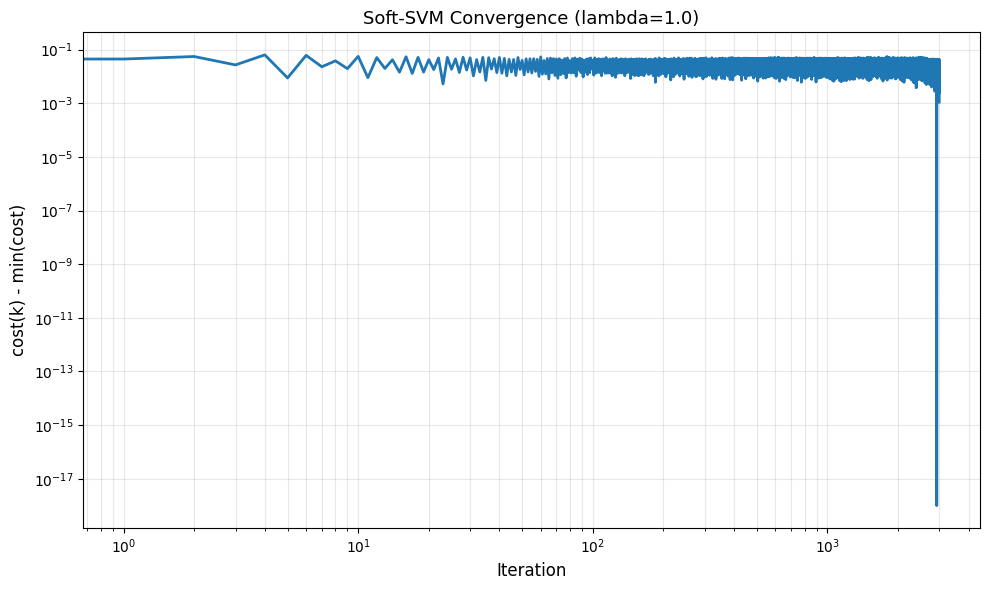

In [25]:
plot_cost_convergence(cost, title=f"Soft-SVM Convergence (lambda={lam})")

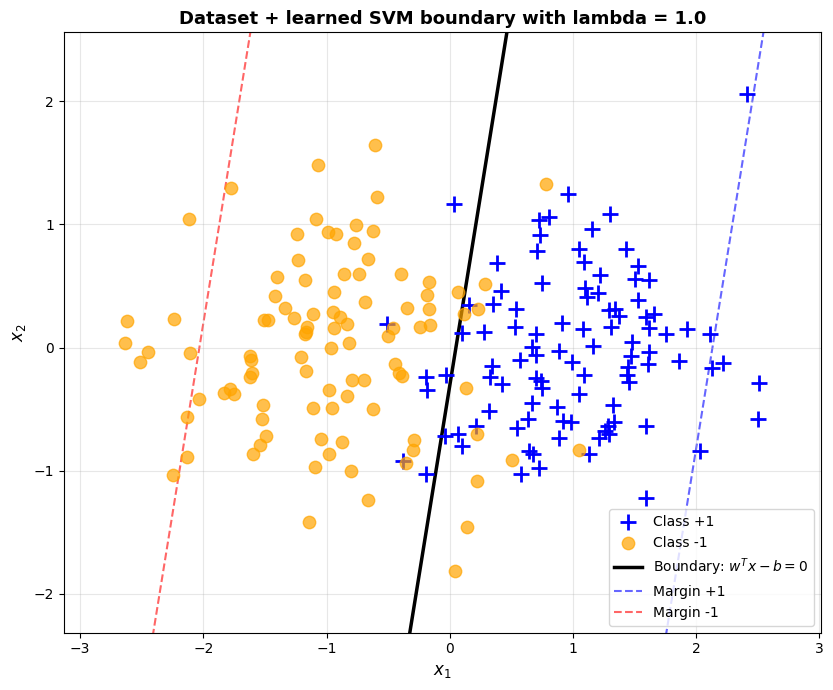

In [26]:
plot_soft_svm_result(X, y, w, b, title=f"Dataset + learned SVM boundary with lambda = {lam}")

**Interpretation**
- The log–log convergence plot shows a fast initial decrease of the objective, followed by small oscillations around the optimum.
  - These oscillations are expected due to the non-smooth hinge loss handled by the proximal operator.
  - Finally, the objective reaches a numerical plateau, indicating convergence of the forward–backward algorithm to the optimal soft-margin SVM solution.
- Due to the overlap between the two classes, some samples lie inside the margin or are misclassified, which is expected in the soft-threshold formulation.
- The parameter $\lambda$ controls the trade-off between margin maximization and hinge-loss penalties.
  - A small value of $\lambda$ leads to a wider margin, resulting in a more flexible model but with a higher risk of underfitting.
  - Conversely, a large value of $\lambda$ produces a narrower margin and fewer training errors, but increases the risk of overfitting, especially when the data are noisy or overlapping.

## **Question 11**

In [27]:
# Load MNIST IDX

def load_idx_images(path):
    with open(path, "rb") as f:
        magic = int.from_bytes(f.read(4), "big")
        if magic != 2051:
            raise ValueError(f"Bad magic number {magic} in {path}")
        n = int.from_bytes(f.read(4), "big")
        rows = int.from_bytes(f.read(4), "big")
        cols = int.from_bytes(f.read(4), "big")
        data = np.frombuffer(f.read(), dtype=np.uint8)
    images = data.reshape(n, rows * cols).astype(np.float64) / 255.0  # (n,784)
    return images.T  # (784, n) to match your convention

def load_idx_labels(path):
    with open(path, "rb") as f:
        magic = int.from_bytes(f.read(4), "big")
        if magic != 2049:
            raise ValueError(f"Bad magic number {magic} in {path}")
        n = int.from_bytes(f.read(4), "big")
        data = np.frombuffer(f.read(), dtype=np.uint8)
    if data.shape[0] != n:
        raise ValueError("Mismatch label count")
    return data.astype(int)  # (n,)

In [28]:
# Choose 2 digits and create train/test m=50

def make_mnist_binary_split(images, labels, d_pos=7, d_neg=1, m_per_class=25, seed=0):
    rng = np.random.default_rng(seed)
    idx_pos = np.where(labels == d_pos)[0]
    idx_neg = np.where(labels == d_neg)[0]
    rng.shuffle(idx_pos)
    rng.shuffle(idx_neg)

    m = 2*m_per_class
    tr_pos = idx_pos[:m_per_class]
    tr_neg = idx_neg[:m_per_class]
    te_pos = idx_pos[m_per_class:2*m_per_class]
    te_neg = idx_neg[m_per_class:2*m_per_class]

    idx_train = np.concatenate([tr_pos, tr_neg])
    idx_test  = np.concatenate([te_pos, te_neg])

    Ytrain = images[:, idx_train]
    Ytest  = images[:, idx_test]
    ytrain = np.concatenate([np.ones(m_per_class), -np.ones(m_per_class)]).astype(float)
    ytest  = np.concatenate([np.ones(m_per_class), -np.ones(m_per_class)]).astype(float)

    return Ytrain, ytrain, Ytest, ytest

In [29]:
# PCA/SVD to 2D and reconstruct one image

def pca2_from_train(Ytrain):
    # Ytrain: (784,m)
    U, S, Vt = np.linalg.svd(Ytrain, full_matrices=False)
    U2 = U[:, :2]  # (784,2)
    return U2

def project(U2, Y):
    return U2.T @ Y  # (2,m)

def show_reconstruction(U2, Y, i=0, title="Reconstruction check"):
    y0 = Y[:, i]
    yhat = U2 @ (U2.T @ y0)

    plt.figure(figsize=(6,3))
    plt.subplot(1,2,1)
    plt.imshow(y0.reshape(28,28).T, cmap="gray")
    plt.title("Original"); plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(yhat.reshape(28,28).T, cmap="gray")
    plt.title("Compressed + Reconstructed"); plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

In [30]:
def build_A_augmented(X, y, eps=1e-8):
    """
    X: (2,m), y: (m,)
    build X~ = [X; -1], Pw = diag([1,1,0])
    A = Dy X~^T inv(XXT) Pw inv(XXT) X~ Dy
    """
    X = np.asarray(X, float)
    y = np.asarray(y, float).reshape(-1)
    n, m = X.shape

    Xaug = np.vstack([X, -np.ones((1, m))])      # (n+1,m)
    Pw = np.eye(n+1)
    Pw[-1, -1] = 0.0

    XXT = Xaug @ Xaug.T                         # (n+1,n+1)
    inv = np.linalg.inv(XXT + eps*np.eye(n+1))

    M = inv @ Pw @ inv
    T = Xaug.T @ M @ Xaug                       # (m,m)
    A = T * np.outer(y, y)
    return A, Xaug, inv

In [31]:
# Power iteration and solver

def power_iteration_lmax(A, n_iter=200, seed=0):
    rng = np.random.default_rng(seed)
    m = A.shape[0]
    v = rng.normal(size=m)
    v /= np.linalg.norm(v) + 1e-12
    for _ in range(n_iter):
        v = A @ v
        nrm = np.linalg.norm(v)
        if nrm < 1e-14:
            return 0.0
        v /= nrm
    return float(v @ (A @ v))

def soft_svm_fb_zeta(X, y, lam=1.0, n_iter=3000, step=None, seed=0):
    X = np.asarray(X, float)
    y = np.asarray(y, float).reshape(-1)
    m = X.shape[1]

    A, Xaug, inv = build_A_augmented(X, y)

    L = power_iteration_lmax(A, seed=seed)
    if step is None:
        step = 0.8 / (L + 1e-12)
    tau_h = step * (lam / m)

    zeta = np.ones(m, float)
    cost = np.zeros(n_iter, float)

    for k in range(n_iter):
        grad = A @ zeta
        ztmp = zeta - step * grad
        zeta = prox_hinge(ztmp, tau_h)

        cost[k] = 0.5 * zeta @ (A @ zeta) + (lam / m) * np.sum(np.maximum(0.0, 1.0 - zeta))

    return zeta, cost, A, Xaug, inv

In [32]:
# Recover w and b

def recover_w_b(zeta, Xaug, y, inv_XXT):
    y = np.asarray(y, float).reshape(-1)
    zeta = np.asarray(zeta, float).reshape(-1)
    w_aug = inv_XXT @ Xaug @ (y * zeta)   # (n+1,)
    w = w_aug[:-1]
    b = w_aug[-1]
    return w, b

In [33]:
def plot_running_min(cost, title="Running minimum of cost"):
    c = np.asarray(cost, float)
    rmin = np.minimum.accumulate(c)
    plt.figure()
    plt.plot(rmin)
    plt.title(title)
    plt.xlabel("Iteration")
    plt.ylabel(r'Best objective value up to iteration $k$')
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_boundary_2d(X, y, w, b, title="Dataset + boundary", pad=0.6):
    X = np.asarray(X, float)
    y = np.asarray(y, float).reshape(-1)
    w = np.asarray(w, float).reshape(-1)
    b = float(b)

    pos = (y == 1)
    neg = (y == -1)

    plt.figure(figsize=(8,6))
    plt.scatter(X[0,pos], X[1,pos], marker="+", s=90, label="+1")
    plt.scatter(X[0,neg], X[1,neg], marker="o", s=60, alpha=0.8, label="-1")

    x_min, x_max = X[0].min()-pad, X[0].max()+pad
    xs = np.linspace(x_min, x_max, 400)

    if abs(w[1]) > 1e-12:
        y0 = (b - w[0]*xs)/w[1]
        y1 = (b + 1 - w[0]*xs)/w[1]
        y_1= (b - 1 - w[0]*xs)/w[1]
        plt.plot(xs, y0, "k-",  lw=2, label=r"$w^Tx-b=0$")
        plt.plot(xs, y1, "b--", lw=1.2, alpha=0.7, label=r"$w^Tx-b=+1$")
        plt.plot(xs, y_1,"r--", lw=1.2, alpha=0.7, label=r"$w^Tx-b=-1$")
    else:
        x0 = b / (w[0] + 1e-12)
        plt.axvline(x0, color="k", lw=2, label=r"$w^Tx-b=0$")

    plt.title(title)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")
    plt.grid(True, alpha=0.3)
    plt.axis("equal")
    plt.legend()
    plt.show()

def error_rate(X, y, w, b):
    scores = (w @ X) - b
    pred = np.sign(scores + 1e-12)
    return np.mean(pred != y)

In [34]:
train_images_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/lab2/train-images.idx3-ubyte"
train_labels_path = "/content/drive/MyDrive/M2-SIGMA-Phelma/convex-optimisation/lab2/train-labels.idx1-ubyte"

images = load_idx_images(train_images_path)
labels = load_idx_labels(train_labels_path)

print(f"images shape: {images.shape}")
print(f"labels shape: {labels.shape}")

images shape: (784, 60000)
labels shape: (60000,)


In [35]:
Ytrain, ytrain, Ytest, ytest = make_mnist_binary_split(
    images, labels, d_pos=7, d_neg=1, m_per_class=25, seed=0
)

print(f"Ytrain shape: {Ytrain.shape}")
print(f"ytrain shape: {ytrain.shape}")
print(f"Ytest shape: {Ytest.shape}")
print(f"ytest shape: {ytest.shape}")

Ytrain shape: (784, 50)
ytrain shape: (50,)
Ytest shape: (784, 50)
ytest shape: (50,)


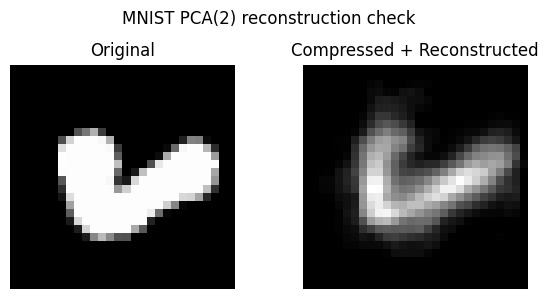

In [36]:
U2 = pca2_from_train(Ytrain)
show_reconstruction(U2, Ytrain, i=0, title="MNIST PCA(2) reconstruction check")

Xtrain = project(U2, Ytrain)   # (2,m)
Xtest  = project(U2, Ytest)

In [37]:
lam = 1
zeta, cost, A, Xaug, inv = soft_svm_fb_zeta(Xtrain, ytrain, lam=lam, n_iter=3000, seed=0)
w, b = recover_w_b(zeta, Xaug, ytrain, inv)

print("w =", w, "b =", b, "||w|| =", np.linalg.norm(w))
print("train err =", error_rate(Xtrain, ytrain, w, b))
print("test  err =", error_rate(Xtest,  ytest,  w, b))

w = [-0.0824755  -0.29938651] b = 0.3094610549847457 ||w|| = 0.31053903052407106
train err = 0.06
test  err = 0.0


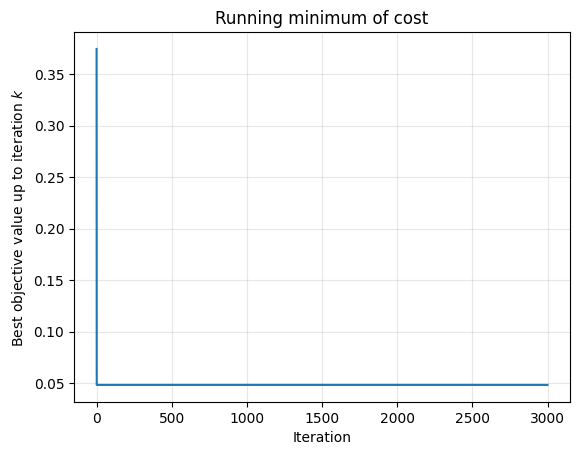

In [38]:
plot_running_min(cost, title="Running minimum of cost")

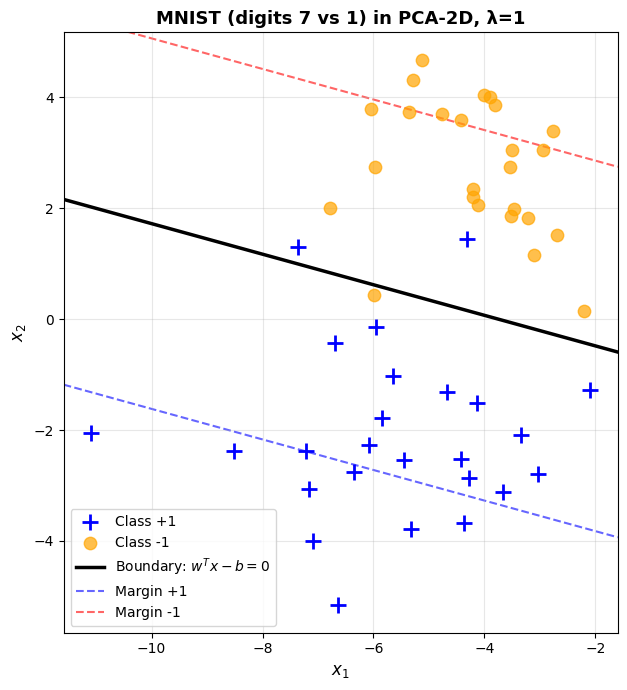

In [39]:
plot_soft_svm_result(Xtrain, ytrain, w, b, title=f"MNIST (digits 7 vs 1) in PCA-2D, λ={lam}")

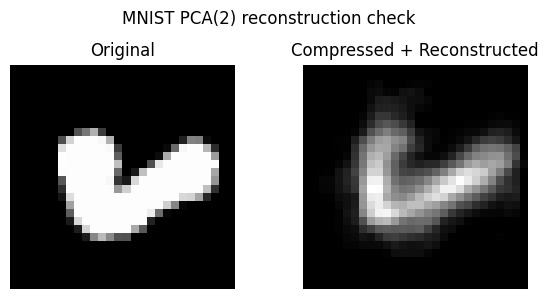

w = [ 0.06332338 -0.33485122] b = -0.06319545087115869 ||w|| = 0.3407861350767271
train err = 0.08
test  err = 0.12


In [40]:
# Same case, 1 vs 7, different lambda

Ytrain, ytrain, Ytest, ytest = make_mnist_binary_split(
    images, labels, d_pos=7, d_neg=1, m_per_class=25, seed=0
)

U2 = pca2_from_train(Ytrain)
show_reconstruction(U2, Ytrain, i=0, title="MNIST PCA(2) reconstruction check")

Xtrain = project(U2, Ytrain)   # (2,m)
Xtest  = project(U2, Ytest)

lam = 10
zeta, cost, A, Xaug, inv = soft_svm_fb_zeta(Xtrain, ytrain, lam=lam, n_iter=3000, seed=0)
w, b = recover_w_b(zeta, Xaug, ytrain, inv)

print("w =", w, "b =", b, "||w|| =", np.linalg.norm(w))
print("train err =", error_rate(Xtrain, ytrain, w, b))
print("test  err =", error_rate(Xtest,  ytest,  w, b))

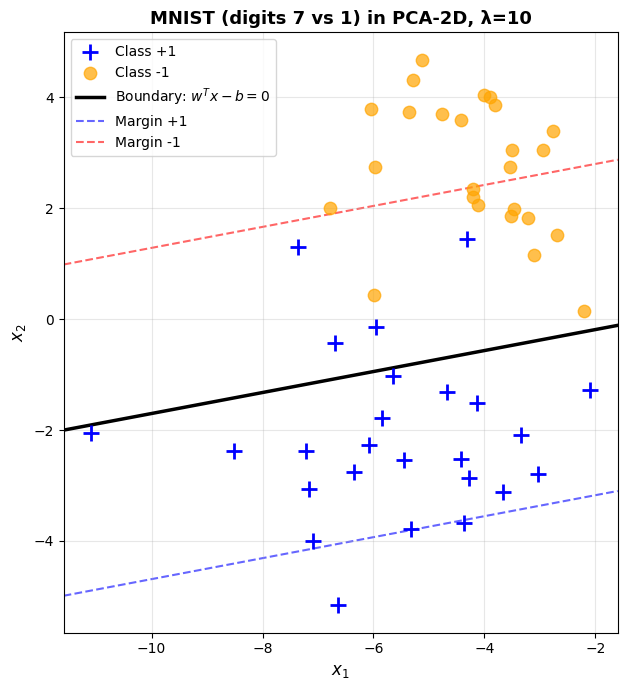

In [41]:
plot_soft_svm_result(Xtrain, ytrain, w, b, title=f"MNIST (digits 7 vs 1) in PCA-2D, λ={lam}")

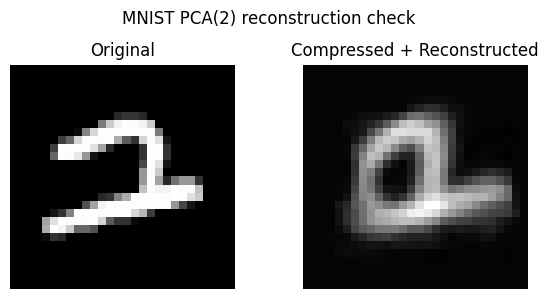

w = [ 0.11231327 -0.06087584] b = 0.0039127528708434445 ||w|| = 0.1277502996713673
train err = 0.46
test  err = 0.46


In [42]:
# Keep lambda = 1, change to case 4 vs 9

Ytrain, ytrain, Ytest, ytest = make_mnist_binary_split(
    images, labels, d_pos=4, d_neg=9, m_per_class=25, seed=0
)

U2 = pca2_from_train(Ytrain)
show_reconstruction(U2, Ytrain, i=0, title="MNIST PCA(2) reconstruction check")

Xtrain = project(U2, Ytrain)   # (2,m)
Xtest  = project(U2, Ytest)

mu = Xtrain.mean(axis=1, keepdims=True)
std = Xtrain.std(axis=1, keepdims=True) + 1e-12

Xtrain = (Xtrain - mu) / std
Xtest  = (Xtest  - mu) / std

lam = 1
zeta, cost, A, Xaug, inv = soft_svm_fb_zeta(Xtrain, ytrain, lam=lam, n_iter=3000, seed=0)
w, b = recover_w_b(zeta, Xaug, ytrain, inv)

print("w =", w, "b =", b, "||w|| =", np.linalg.norm(w))
print("train err =", error_rate(Xtrain, ytrain, w, b))
print("test  err =", error_rate(Xtest,  ytest,  w, b))

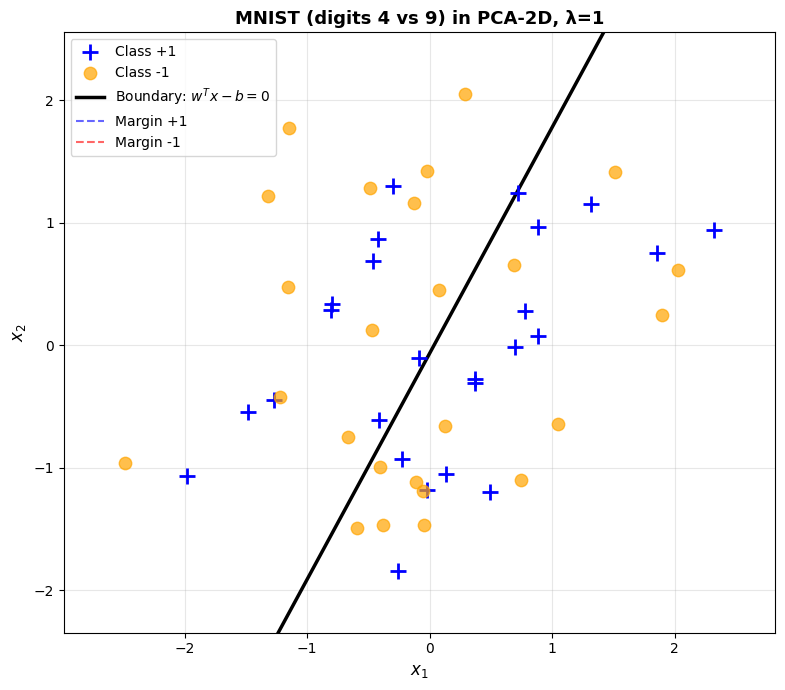

In [43]:
plot_soft_svm_result(Xtrain, ytrain, w, b, title=f"MNIST (digits 4 vs 9) in PCA-2D, λ={lam}")

**Interpretation**

**Case 1 vs 7, lambda = 1**
- Convergence of the soft-SVM objective
  - The plot shows the running minimum of the objective value along the forward–backward iterations.
  - After a rapid initial decrease, the objective quickly reaches a plateau, indicating convergence of the algorithm.
  - The flat region reflects small oscillations around the optimum due to the non-smooth hinge loss.
- Soft-SVM decision boundary in PCA-2D:
  - The MNIST images of digits 7 and 1 are projected onto a two-dimensional PCA subspace.
  - The learned soft-margin SVM boundary separates the two classes while allowing margin violations due to the overlap between the projected data.

**Comparison Between Digit Pairs: 1 vs 7 and 4 vs 9 ($\lambda = 1$)**

With the same regularization parameter $\lambda=1$, the classification behavior differs significantly between the two digit pairs.
- For digits 1 vs 7, the classes are relatively well separated in the PCA-2D space, leading to a clear decision boundary and a small number of margin violations.
- In contrast, digits 4 vs 9 exhibit a much stronger overlap after projection, resulting in a less distinct separation and more points lying close to or inside the margin.

**Effect of Regularization Parameter: Case 1 vs 7 ($\lambda$ = 1 vs $\lambda$ = 10)**

For digits 1 vs 7, increasing the regularization parameter from $\lambda=1$ to $\lambda=10$ leads to a stricter penalization of margin violations.
- With higher $\lambda$, the SVM places more emphasis on reducing hinge-loss violations, producing a tighter margin and fewer training errors, while the overall decision boundary remains similar due to the good separability of the two digits.
- We can easily observe that there are only 4 classification errors for $\lambda=10$, whereas there are more than 10 errors for $\lambda=1$.


# **3. Splitting the cost function with an augmented Lagrangian approach**


- **Forward step ($\tilde w$-update)** Perform one gradient-descent steps on $L_\rho$ with respect to $\tilde w$ (smooth quadratic), which decreases the objective and reduces the residual $\zeta - D_y\tilde X^T\tilde w$.
- **Backward step ($\zeta$-update)** Update $\zeta$ by the proximal operator of the hinge loss:
\begin{equation*}
\zeta \leftarrow \mathrm{prox}_{\frac{\lambda}{m\rho} f_1}\!\left(D_y\tilde X^T\tilde w - \frac{1}{\rho}\eta\right),
\qquad f_1(z)=\max(0,1-z).
\end{equation*}
- **Dual step** Dual ascent on the multiplier to enforce feasibility:
\begin{equation*}
\eta \leftarrow \eta + \rho\big(\zeta - D_y\tilde X^T\tilde w\big).
\end{equation*}

In [44]:
def power_iteration_lmax_matvec(matvec, dim, n_iter=200, seed=0):
    """
    Largest eigenvalue estimate using only matvec.
    """
    rng = np.random.default_rng(seed)
    v = rng.normal(size=dim)
    v /= (np.linalg.norm(v) + 1e-12)
    for _ in range(n_iter):
        w = matvec(v)
        nrm = np.linalg.norm(w)
        if nrm < 1e-14:
            return 0.0
        v = w / nrm
    return float(v @ matvec(v))

In [45]:
def soft_svm_augmented_lagrangian(X, y, lam=1.0, rho=1.0,
    n_outer=2000, gd_steps=1, step_w=None,
    seed=0, verbose=True):
    """
    Augmented Lagrangian iterations for soft-threshold SVM.
    """
    X = np.asarray(X, float)
    y = np.asarray(y, float).reshape(-1)
    n, m = X.shape

    Xtilde = np.vstack([X, -np.ones((1, m))])

    Pw = np.eye(n + 1)
    Pw[-1, -1] = 0.0

    def A_of(wtilde):
        return y * (Xtilde.T @ wtilde)  # (m,)

    C = Xtilde @ Xtilde.T  # (n+1,n+1)

    def M_matvec(v):
        return (Pw @ v) + rho * (C @ v)

    if step_w is None:
        Lw = power_iteration_lmax_matvec(M_matvec, dim=n+1, n_iter=200, seed=seed)
        step_w = 0.99 / (Lw + 1e-12)
        if verbose:
            print(f"[w-step] Estimated Lw={Lw:.6e} => step_w={step_w:.6e}")

    tau_z = lam / (m * rho)

    wtilde = np.zeros(n + 1, float)
    zeta = np.ones(m, float)
    eta = np.zeros(m, float)

    obj = np.zeros(n_outer, float)
    prim_res = np.zeros(n_outer, float)

    for k in range(n_outer):
        for _ in range(gd_steps):
            Aw = A_of(wtilde)             # (m,)
            r = Aw - zeta                # (m,)
            grad = (Pw @ wtilde) + (Xtilde @ (y * (rho * r - eta)))
            wtilde = wtilde - step_w * grad

        # prox
        Aw = A_of(wtilde)
        zeta = prox_hinge(Aw - eta / rho, tau_z)

        # dual ascent
        eta = eta + rho * (zeta - Aw)

        obj[k] = 0.5 * (wtilde @ (Pw @ wtilde)) + (lam / m) * np.sum(np.maximum(0.0, 1.0 - zeta))
        prim_res[k] = np.linalg.norm(zeta - Aw)

        if verbose and (k + 1) % 500 == 0:
            print(f"Iter {k+1:4d}: obj={obj[k]:.6f}, ||zeta - Aw||={prim_res[k]:.3e}")

    w = wtilde[:-1]
    b = float(wtilde[-1])

    hist = {"obj": obj, "prim_res": prim_res, "step_w": step_w, "tau_z": tau_z}
    return w, b, zeta, eta, hist

In [50]:
def plot_augLag_history(hist, title="Augmented Lagrangian convergence"):
    obj = hist["obj"]
    r = hist["prim_res"]

    # log-log on objective gap
    rel = obj - np.min(obj)
    rel = np.maximum(rel, 1e-18)

    plt.figure()
    plt.semilogy(np.maximum(r, 1e-18))
    plt.title(title + " (primal residual)")
    plt.xlabel("Iteration")
    plt.ylabel("||zeta - Dy X~^T w~||")
    plt.grid(True, alpha=0.3, which="both")
    plt.show()

In [47]:
lam = 1.0
rho = 1.0

w, b, zeta, eta, hist = soft_svm_augmented_lagrangian(
    Xtrain, ytrain, lam=lam, rho=rho,
    n_outer=3000, gd_steps=1, step_w=None,
    seed=0, verbose=True
)

print("w =", w, "b =", b, "||w|| =", np.linalg.norm(w))
print("train err =", error_rate(Xtrain, ytrain, w, b))
print("test  err =", error_rate(Xtest,  ytest,  w, b))

[w-step] Estimated Lw=6.389280e+01 => step_w=1.549470e-02
Iter  500: obj=0.995449, ||zeta - Aw||=6.606e-17
Iter 1000: obj=0.995449, ||zeta - Aw||=5.672e-17
Iter 1500: obj=0.995449, ||zeta - Aw||=5.172e-17
Iter 2000: obj=0.995449, ||zeta - Aw||=6.270e-17
Iter 2500: obj=0.995449, ||zeta - Aw||=5.267e-17
Iter 3000: obj=0.995449, ||zeta - Aw||=5.267e-17
w = [ 0.09169231 -0.02634905] b = -7.300343017057095e-16 ||w|| = 0.09540310098756018
train err = 0.42
test  err = 0.46


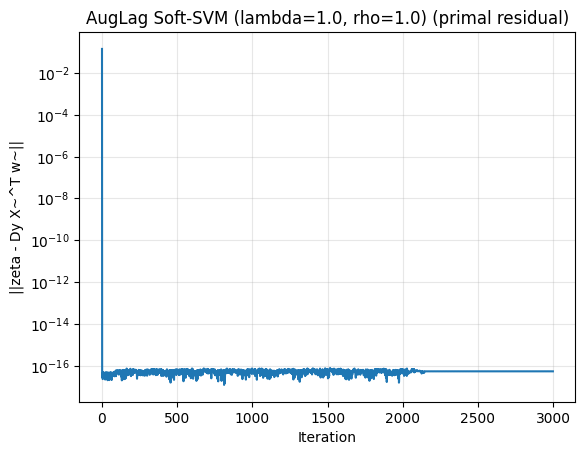

In [51]:
plot_augLag_history(hist, title=f"AugLag Soft-SVM (lambda={lam}, rho={rho})")

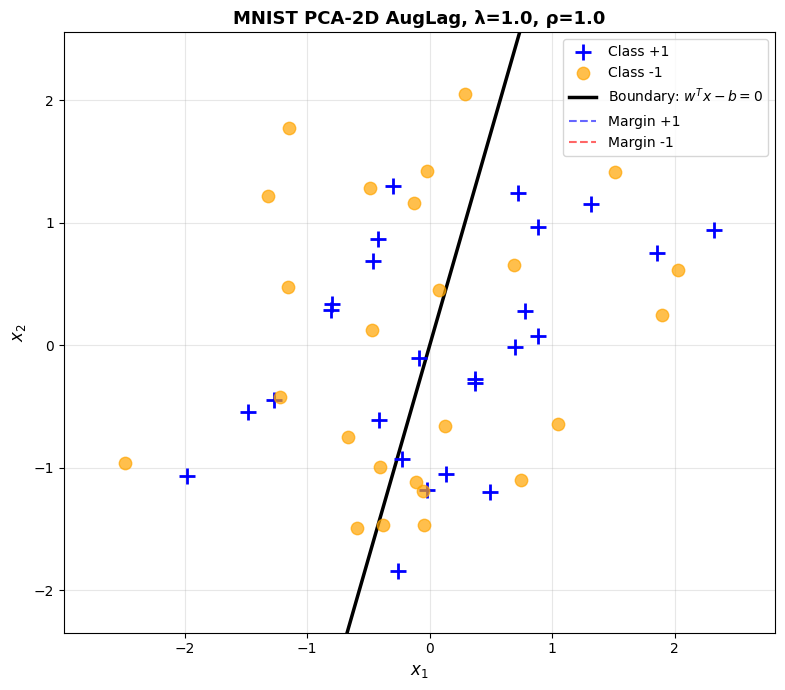

In [49]:
plot_soft_svm_result(Xtrain, ytrain, w, b, title=f"MNIST PCA-2D AugLag, lambda={lam}, rho={rho}")

**Interpretation**

- The learned decision boundary is a soft-margin separator: some samples remain inside the margin, which is expected with overlapping classes and finite $\lambda$.
- The primal residual decreases, showing that the constraint is progessively enforced by the dual update.